## Data-Mining Practice 2
### Myrzakassymov Azizkhan

### About Dataset
#### Overview
The Student Exam Performance & Academic Success Dataset is a large-scale, semi-synthetic dataset containing 100,000 student records across 44 features.

Unlike purely random datasets, this dataset was engineered using non-linear physics and calibrated score standardization. It includes realistic interactions among student habits, socioeconomic backgrounds, study behaviors, and mental wellbeing, offering an ideal sandbox for machine learning modeling, data cleaning, and exploratory analysis.

#### Key Target Variables
This dataset supports multiple machine learning tasks with four distinct targets:

exam_score (Numeric / Continuous): Final score ranging from 0 to 100. Ideal for Regression.

pass_status (Binary / Categorical): Pass (≥50) or Fail (<50). Ideal for Binary Classification.

performance_grade (Multi-Class Categorical): Standard letter grades (A, B, C, D, F) based on a realistic academic distribution (~77% pass rate).

performance_level (Multi-Class Categorical): Performance categories (High, Medium, Low).

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('student_exam_performance.csv')

display(df.info())
display(df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  object 
 3   education_level             100000 non-null  object 
 4   school_type                 100000 non-null  object 
 5   family_income               100000 non-null  object 
 6   parent_education            93474 non-null   object 
 7   urban_rural                 100000 non-null  object 
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  object 
 13  study_hours_per

None

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,...,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,...,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,...,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,...,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High


#### Task 1. Data Exploration

1.	Pick two numeric attributes from your dataset. For the first, plot a histogram and a box plot, and apply the box plot algorithm from the lecture (find Q1, Q3, IQR, then flag any value outside Q1 − 1.5×IQR or Q3 + 1.5×IQR) to list the outliers it detects. For the second, produce a scatter plot against the first attribute and state whether the relationship looks positive, negative, or unrelated.

a.	Show the Q1, Q3, IQR, and the lower/upper bounds you computed, not just the final outlier list.


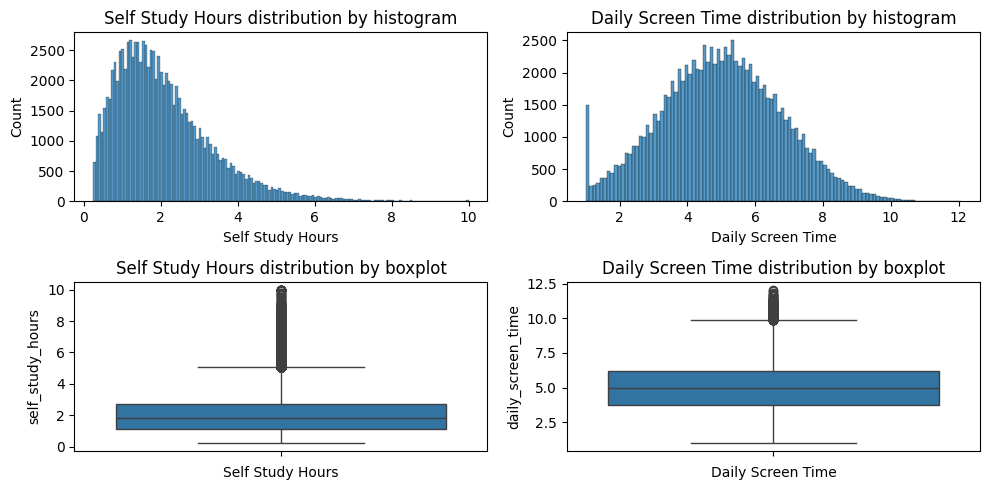

Series of outliers in numerical columns


,self_study_hours,daily_screen_time
3,5.51,5.12
59,5.76,3.36
121,8.14,5.67
138,5.90,5.61
148,5.39,4.93
...,...,...
99841,7.01,8.77
99946,5.64,5.83
99974,5.86,5.78
99979,6.83,6.46


Upperbounds and lowerbounds and IQR respectfully for each column


self_study_hours     5.07
daily_screen_time    9.87
dtype: float64

self_study_hours    -1.17
daily_screen_time    0.11
dtype: float64

self_study_hours     1.56
daily_screen_time    2.44
dtype: float64

In [4]:
# choosing numerical columns
numerical = {
    'Self Study Hours' : 'self_study_hours',
    'Daily Screen Time' : 'daily_screen_time'
}

fig, ax = plt.subplots(ncols=2, nrows=2, figsize=(10, 5))
ax = ax.flatten()

# numerical columns plots 
for numeric, i in zip(numerical, range(0, len(ax))):
    column = numerical[numeric]
    title = numeric + ' distribution by histogram'
    sns.histplot(df[column], ax=ax[i]) # histogram
    ax[i].set_title(title)
    ax[i].set_xlabel(numeric)
for numeric, i in zip(numerical, range(2, len(ax))):
    column = numerical[numeric]
    title = numeric + ' distribution by boxplot'
    sns.boxplot(df[column], ax=ax[i]) # boxplot
    ax[i].set_title(title)
    ax[i].set_xlabel(numeric)



plt.tight_layout()
plt.show()

# IQR 
q1 = df[numerical.values()].quantile(0.25) 
q3 = df[numerical.values()].quantile(0.75)
iqr = q3 - q1

lowerbound = q1 - (iqr * 1.5) 
upperbound = q3 + (iqr * 1.5) 

outliers = df[(df[numerical.values()].lt(lowerbound).any(axis=1)) | (df[numerical.values()].gt(upperbound).any(axis=1))][numerical.values()]
print('Series of outliers in numerical columns')
display(outliers)

# a.
print('Upperbounds and lowerbounds and IQR respectfully for each column')
display(upperbound, lowerbound, iqr)

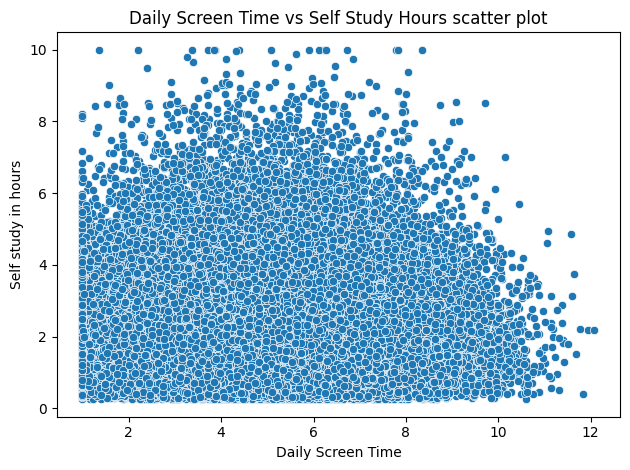

In [5]:
# scatter plot
fig = plt.plot(figsize = (6, 8))
fig = sns.scatterplot(data = df[numerical.values()], x = numerical['Daily Screen Time'], y = numerical['Self Study Hours'])

fig.set_title('Daily Screen Time vs Self Study Hours scatter plot')
fig.set_xlabel('Daily Screen Time')
fig.set_ylabel('Self study in hours')

plt.tight_layout()
plt.show()

This doesn't look related at all.

#### Task 2. Variable Transformation

2.	Take one numeric attribute and apply (a) a simple functional transformation (log or sqrt, as covered in the lecture) and (b) Min-Max normalization and (c) Z-score normalization. Report min, max, mean, and standard deviation before and after each transformation in one table. 

a.	State in 1-2 sentences which of the three transformed versions you would use before computing distances, and why.


In [6]:
numerical = ['previous_gpa']
log_x = np.log(df[numerical] + 1)
minmax_x = (df[numerical] - df[numerical].min()) / (df[numerical].max() - df[numerical].min())
zscore_x = (df[numerical] - df[numerical].mean()) / df[numerical].std()

transformations = {
    'log transformation' : log_x,
    'min-max transformation' : minmax_x,
    'z-score transformation' : zscore_x
}

for i in transformations:
    print('For', i)
    table = pd.concat(
        {
            'before' : df[numerical].agg(['mean', 'min', 'max', 'std']), # before
            'after' : transformations[i].agg(['mean', 'min', 'max', 'std']) # after
        }, 
        axis=1,
    )
    display(table)

For log transformation


,before,after
,previous_gpa,previous_gpa
mean,2.780892,1.321750
min,1.000000,0.693147
max,4.000000,1.609438
std,0.478218,0.129249


For min-max transformation


,before,after
,previous_gpa,previous_gpa
mean,2.780892,0.593631
min,1.000000,0.000000
max,4.000000,1.000000
std,0.478218,0.159406


For z-score transformation


,before,after
,previous_gpa,previous_gpa
mean,2.780892,-4.192038e-17
min,1.000000,-3.724020e+00
max,4.000000,2.549275e+00
std,0.478218,1.000000e+00


if we look on z-score, mean is very close to 0 and std is just 1.

#### Task 7. Kernel Functions

7.	Using the formulas from the lecture, compute the linear kernel K(x,x') = xᵀx' and the RBF kernel K(x,x') = exp(−γ‖x−x'‖²) for a sample of 10 rows (standardized numeric attributes, pick γ = 0.5). Report both kernel matrices, and for the single most different pair of rows, explain in 2-3 sentences why its linear kernel score and RBF kernel score disagree.


In [53]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

numeric = df.select_dtypes(include='int64').sample(15)

standard_sampling = scaler.fit_transform(numeric)
gamma = -0.5

linear_kernel = standard_sampling @ standard_sampling.T
rbf_kernel = np.exp(gamma * np.sum(standard_sampling**2, 1)[:,None] + np.sum(standard_sampling**2, 1)[None,:] -  2 * linear_kernel)
display(standard_sampling)


display(linear_kernel)
display(rbf_kernel)

array([[ 0.74387316, -0.60302269,  2.04253105,  0.58722022,  0.5       ,
        -1.4891087 ,  0.68721607, -0.06926612],
       [-0.22639618, -0.60302269, -0.2438843 , -2.05527077,  0.5       ,
         0.86211556,  0.26647154,  0.48078836],
       [-1.19666552, -0.60302269, -1.61573352,  0.58722022,  0.5       ,
        -0.78374142,  1.10796061,  0.60302269],
       [-1.19666552,  1.6583124 ,  0.21339877,  0.58722022, -2.        ,
         1.68504405,  0.05609927,  1.39754583],
       [-0.22639618, -0.60302269, -0.2438843 , -1.17444044,  0.5       ,
         1.33236041,  0.05609927,  0.48078836],
       [ 1.22900783, -0.60302269, -0.70116737, -2.05527077,  0.5       ,
         0.2743095 ,  0.26647154,  1.64201448],
       [-1.68180019, -0.60302269,  1.12796491,  0.58722022,  0.5       ,
        -0.07837414, -1.62687887, -0.43596911],
       [ 1.22900783,  1.6583124 , -0.2438843 ,  0.58722022, -2.        ,
        -0.66618021, -1.62687887, -1.78054672],
       [ 0.74387316, -0.60302269

array([[ 8.37825276e+00, -2.39377410e+00, -1.34517382e+00,
        -4.67693019e+00, -2.72134962e+00, -1.45027949e+00,
         1.04020947e+00, -1.24175874e+00,  6.73415164e+00,
         1.45746592e+00, -3.44327969e+00, -7.62727588e-01,
         3.23234758e+00, -3.34232183e+00,  5.35167694e-01],
       [-2.39377410e+00,  5.99391685e+00, -1.87970586e-02,
        -8.48445331e-01,  4.53291921e+00,  5.82749035e+00,
        -1.19829334e+00, -5.28956706e+00, -1.71440576e+00,
        -2.41147875e+00, -2.26827794e+00,  2.79524057e+00,
         2.57545111e-01, -1.48705100e-02, -3.24920225e+00],
       [-1.34517382e+00, -1.87970586e-02,  7.20653080e+00,
        -9.83690780e-01, -1.03190234e-01,  1.39352387e-01,
        -8.55466359e-01, -5.08594642e+00,  9.17437940e-01,
         3.10542294e+00, -3.26012919e+00,  2.88603241e+00,
        -1.27530242e-04,  1.30532287e+00, -3.90757795e+00],
       [-4.67693019e+00, -8.48445331e-01, -9.83690780e-01,
         1.33680299e+01,  4.49377610e-01, -2.05527316

array([[3.48382705e-06, 7.29484897e+02, 3.01193245e+02, 1.11860589e+08,
        2.14164242e+02, 4.41943516e+03, 5.11727348e+00, 5.51300909e+05,
        1.73169253e-05, 3.00389379e+00, 1.38127418e+05, 2.81808722e+01,
        2.01041862e-03, 8.10725850e+02, 8.87021776e+01],
       [2.60778749e+04, 1.24541038e-04, 6.99070495e+01, 1.74200490e+05,
        3.52793910e-04, 6.94589425e-03, 1.48295997e+03, 5.95692733e+09,
        1.24321563e+03, 2.26965155e+04, 4.33948616e+04, 7.53866626e-02,
        2.54049918e+00, 3.43904998e+00, 5.65911101e+05],
       [1.74644052e+03, 1.13389711e+01, 2.02006413e-05, 1.24510593e+05,
        2.04681599e+00, 3.30419946e+02, 4.07415849e+02, 2.16194127e+09,
        3.50945999e+00, 1.99858896e-01, 1.72041645e+05, 3.42860897e-02,
        2.31960960e+00, 1.33788046e-01, 1.15156991e+06],
       [6.28243600e+04, 2.73680875e+00, 1.20600387e+01, 1.95662482e-09,
        3.11294851e-02, 1.22276009e+03, 5.40440589e+00, 9.01880878e+01,
        5.97989465e+03, 9.40276005e+0